# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox.

## Import the required packages

In [ ]:
from aitlas.datasets import ForestNetDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import csv

## Visualize images and masks

In [24]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/forestnet/examples",
    "csv_file": "/home/dragik/data/FAIR_EO/forestnet/train.csv"
}
dataset = ForestNetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1616


# Show images

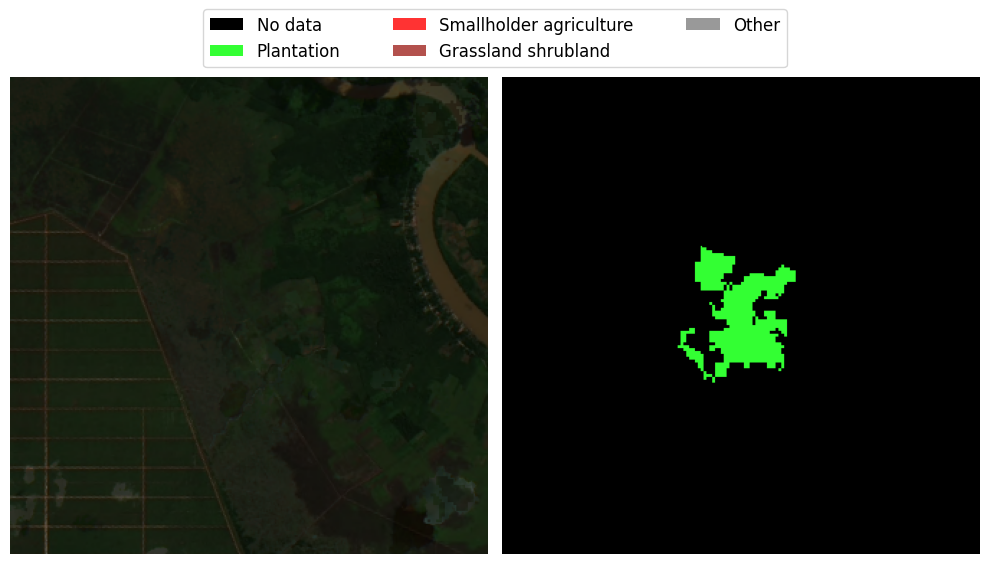

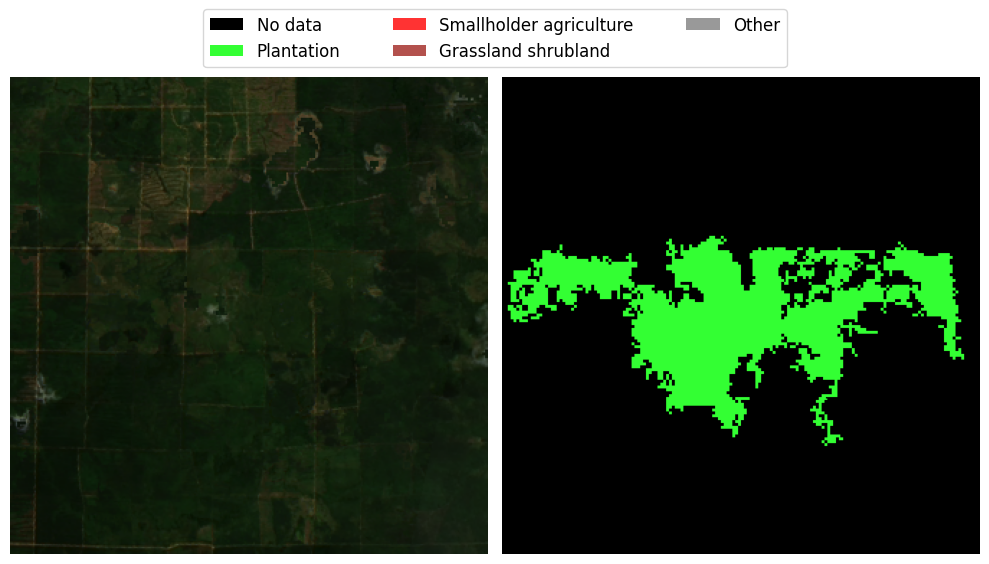

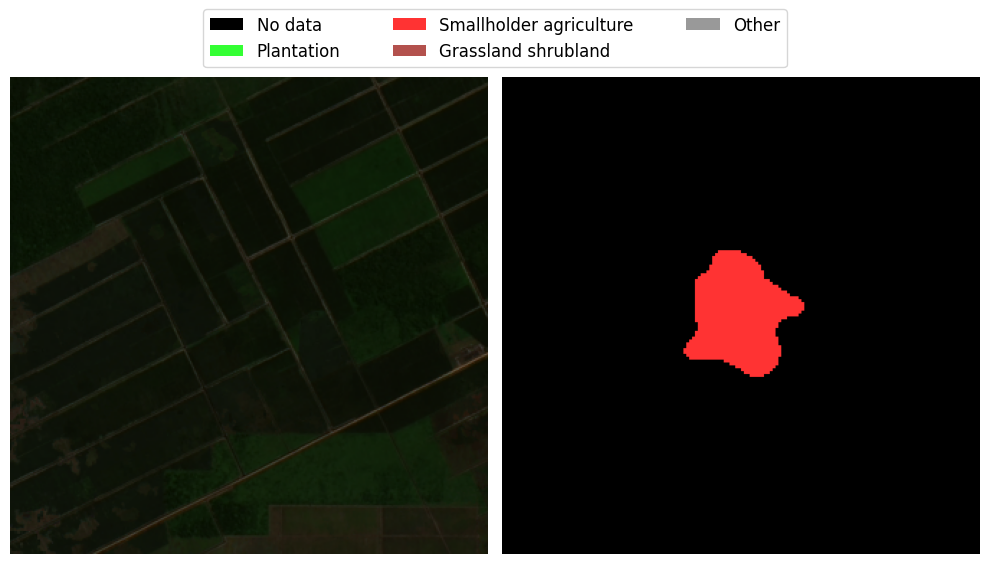

In [25]:
dataset.show_image(15)
dataset.show_image(150)
dataset.show_image(281);

In [9]:
dataset.data_distribution_table()

,Label,Number of pixels
0,Smallholder agriculture,447606
1,Grassland shrubland,808587
2,Plantation,2149306
3,Other,96349


2025-07-10 11:12:44,192 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-07-10 11:12:44,197 INFO Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


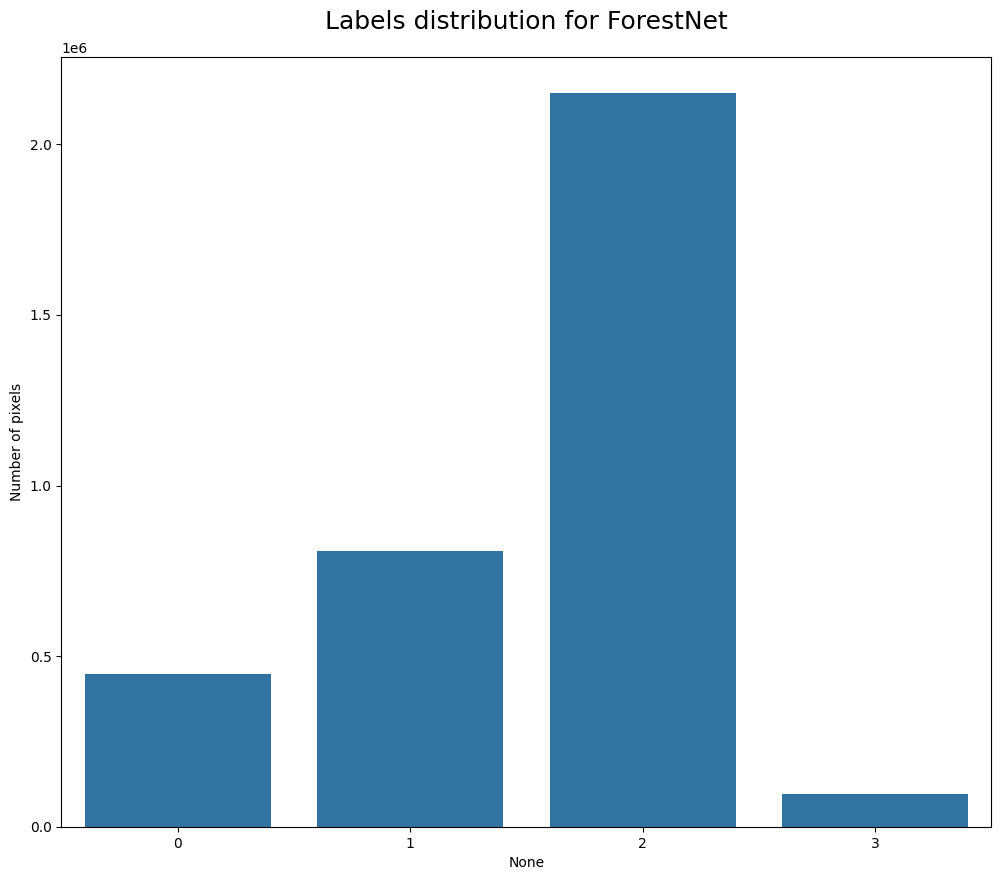

In [10]:
dataset.data_distribution_barchart();

## Load training data ##

In [37]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/forestnet/examples",
    "csv_file": "/home/dragik/data/FAIR_EO/forestnet/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = ForestNetDataset(train_dataset_config)
len(train_dataset)

1616

## Create the model ##

In [38]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/forestnet"
model_config = {
    "num_classes": 5, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [39]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-07-10 11:33:33,907 INFO Starting training.
training: 100%|██████████| 101/101 [00:16<00:00,  6.09it/s]
2025-07-10 11:33:50,573 INFO epoch: 1, time: 17, loss:  0.60223
testing on train set: 100%|██████████| 101/101 [00:06<00:00, 15.10it/s]
2025-07-10 11:33:59,261 INFO IOU:0.6749741465150837, IOU mean:0.20994891459241244, IOU per Class:[0.92803195 0.05778302 0.05293514 0.00972791 0.00126655]
training: 100%|██████████| 101/101 [00:16<00:00,  6.00it/s]
2025-07-10 11:34:16,086 INFO epoch: 2, time: 17, loss:  0.44009
testing on train set: 100%|██████████| 101/101 [00:06<00:00, 15.00it/s]
2025-07-10 11:34:22,840 INFO IOU:0.8756362951286942, IOU mean:0.20233688961170365, IOU per Class:[0.9351423  0.07654214 0.         0.         0.        ]
training: 100%|██████████| 101/101 [00:16<00:00,  5.96it/s]
2025-07-10 11:34:39,804 INFO epoch: 3, time: 17, loss:  0.27796
testing on train set: 100%|██████████| 101/101 [00:06<00:00, 15.17it/s]
2025-07-10 11:34:46,481 INFO IOU:0.9216019391207216, IOU

0.041348462057585765

## Evaluate the model ##

In [40]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/forestnet/examples",
    "csv_file": "/home/dragik/data/FAIR_EO/forestnet/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = ForestNetDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/forestnet/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

473


2025-07-10 11:41:38,159 INFO Loading checkpoint /home/dragik/data/FAIR_EO/forestnet/checkpoint.pth.tar
2025-07-10 11:41:38,588 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/forestnet/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 119/119 [00:02<00:00, 39.72it/s]


[{'IOU': 0.9095302051962834,
  'IOU mean': 0.1897475865643251,
  'IOU per Class': array([0.94873793, 0.        , 0.        , 0.        , 0.        ])}]

## Predictions ##

2025-07-10 11:41:41,606 INFO Loading checkpoint /home/dragik/data/FAIR_EO/forestnet/checkpoint.pth.tar
2025-07-10 11:41:42,039 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/forestnet/checkpoint.pth.tar at epoch 21


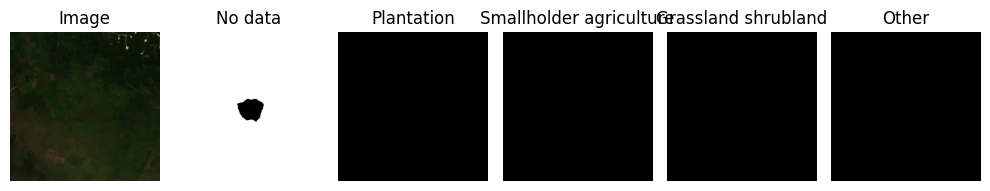

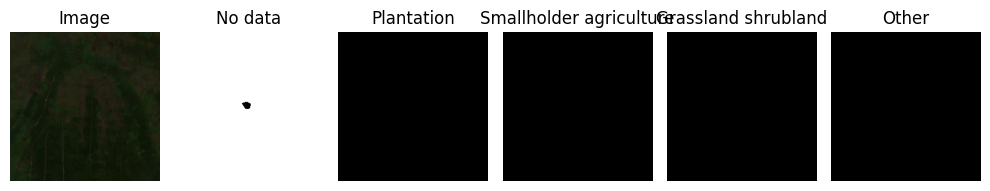

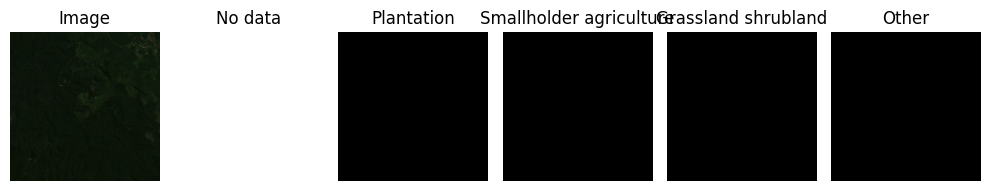

In [41]:
model_path = "/home/dragik/data/FAIR_EO/forestnet/checkpoint.pth.tar"
labels = ["No data","Plantation", "Smallholder agriculture", "Grassland shrubland", "Other"]
transform = ResizeToTensor()
model.load_model(model_path)
csv_file = "/home/dragik/data/FAIR_EO/forestnet/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[5])

image = image_loader('/home/dragik/data/FAIR_EO/forestnet/' + test_list[1] + '/images/visible/composite.png')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/forestnet/' + test_list[10] + '/images/visible/composite.png')
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/forestnet/' + test_list[50] + '/images/visible/composite.png')
fig = model.predict_masks(image, labels, transform)